In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from itertools import product
from scipy.signal import find_peaks


In [2]:
class StockLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super(StockLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, 
                             batch_first=True, dropout=0.4)
        self.fc_layers = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, output_size)
        )
    
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc_layers(out[:, -1, :])
        return out

In [25]:
def compute_technical_indicators(data):
    """
    Compute custom technical indicators and merge sentiment scores based on dates.
    
    Parameters:
        data (pd.DataFrame): The input data containing columns such as 'Close', 'Open', 'High', 'Low', 'Volume', etc.
        df (pd.DataFrame): DataFrame containing 'Date' and 'compound_score' columns for sentiment analysis.
    
    Returns:
        pd.DataFrame: DataFrame with new columns for each technical indicator and the 'Scores' column populated.
    """
    # Ensure 'Date' columns are in datetime format
    
    # ======= Compute Technical Indicators =======
    # 1. Moving Average Convergence Divergence (MACD)
    data['EMA_12'] = data['Close'].ewm(span=12, adjust=False).mean()
    data['EMA_26'] = data['Close'].ewm(span=26, adjust=False).mean()
    data['MACD'] = data['EMA_12'] - data['EMA_26']
    data['MACD_Signal'] = data['MACD'].ewm(span=9, adjust=False).mean()
    
    # 2. Relative Strength Index (RSI)
    delta = data['Close'].diff()
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    window_length = 14
    avg_gain = gain.rolling(window=window_length, min_periods=window_length).mean()
    avg_loss = loss.rolling(window=window_length, min_periods=window_length).mean()
    rs = avg_gain / avg_loss
    data['RSI'] = 100 - (100 / (1 + rs))
    data['RSI'].fillna(0, inplace=True)
    
    # 3. Average True Range (ATR)
    data['HL'] = data['High'] - data['Low']
    data['HC'] = abs(data['High'] - data['Close'].shift(1))
    data['LC'] = abs(data['Low'] - data['Close'].shift(1))
    data['TR'] = data[['HL', 'HC', 'LC']].max(axis=1)
    atr_window = 14
    data['ATR'] = data['TR'].rolling(window=atr_window, min_periods=atr_window).mean()
    data['ATR'].fillna(0, inplace=True)
    
    # 4. Money Flow Index (MFI)
    data['TP'] = (data['High'] + data['Low'] + data['Close']) / 3
    data['RMF'] = data['TP'] * data['Volume']
    data['PMF'] = np.where(data['Close'] > data['Close'].shift(1), data['RMF'], 0)
    data['NMF'] = np.where(data['Close'] < data['Close'].shift(1), data['RMF'], 0)
    mfi_window = 14
    positive_mf = data['PMF'].rolling(window=mfi_window, min_periods=mfi_window).sum()
    negative_mf = data['NMF'].rolling(window=mfi_window, min_periods=mfi_window).sum()
    money_ratio = positive_mf / negative_mf
    data['MFI'] = 100 - (100 / (1 + money_ratio))
    data['MFI'].fillna(0, inplace=True)
    
    # 5. Bollinger Bands (BB)
    bb_window = 20
    bb_std = 2
    data['BB_Middle'] = data['Close'].rolling(window=bb_window, min_periods=bb_window).mean()
    data['BB_Std'] = data['Close'].rolling(window=bb_window, min_periods=bb_window).std()
    data['BB_Upper'] = data['BB_Middle'] + (bb_std * data['BB_Std'])
    data['BB_Lower'] = data['BB_Middle'] - (bb_std * data['BB_Std'])
    data[['BB_Middle', 'BB_Std', 'BB_Upper', 'BB_Lower']] = data[['BB_Middle', 'BB_Std', 'BB_Upper', 'BB_Lower']].fillna(method='bfill')
    
    # 6. Stochastic Oscillator (SO)
    so_window = 14
    data['SO_Low'] = data['Low'].rolling(window=so_window, min_periods=so_window).min()
    data['SO_High'] = data['High'].rolling(window=so_window, min_periods=so_window).max()
    data['SO_%K'] = ((data['Close'] - data['SO_Low']) / (data['SO_High'] - data['SO_Low'])) * 100
    data['SO_%D'] = data['SO_%K'].rolling(window=3, min_periods=3).mean()
    data['SO_%K'].fillna(0, inplace=True)
    data['SO_%D'].fillna(0, inplace=True)
    
    # 7. Average Directional Index (ADX)
    data['+DM'] = np.where(
        (data['High'] - data['High'].shift(1)) > (data['Low'].shift(1) - data['Low']),
        np.maximum(data['High'] - data['High'].shift(1), 0),
        0
    )
    data['-DM'] = np.where(
        (data['Low'].shift(1) - data['Low']) > (data['High'] - data['High'].shift(1)),
        np.maximum(data['Low'].shift(1) - data['Low'], 0),
        0
    )
    data['TR_Smoothed'] = data['TR'].rolling(window=atr_window, min_periods=atr_window).sum()
    data['+DM_Smoothed'] = data['+DM'].rolling(window=atr_window, min_periods=atr_window).sum()
    data['-DM_Smoothed'] = data['-DM'].rolling(window=atr_window, min_periods=atr_window).sum()
    data['+DI'] = (data['+DM_Smoothed'] / data['TR_Smoothed']) * 100
    data['-DI'] = (data['-DM_Smoothed'] / data['TR_Smoothed']) * 100
    data['DX'] = (abs(data['+DI'] - data['-DI']) / (data['+DI'] + data['-DI'])) * 100
    data['ADX'] = data['DX'].rolling(window=atr_window, min_periods=atr_window).mean()
    data['ADX'].fillna(0, inplace=True)
    
    # 8. MACD Histogram
    data['MACD_Histogram'] = data['MACD'] - data['MACD_Signal']
    data['MACD_Histogram'].fillna(0, inplace=True)
    
    # 9. Volume-Weighted Average Price (VWAP)
    data['Cumulative_TP_Volume'] = (data['Close'] * data['Volume']).cumsum()
    data['Cumulative_Volume'] = data['Volume'].cumsum()
    data['VWAP'] = data['Cumulative_TP_Volume'] / data['Cumulative_Volume']
    data['VWAP'].fillna(0, inplace=True)
    
    # 10. Chaikin Money Flow (CMF)
    cmf_window = 20
    data['MFM'] = ((data['Close'] - data['Low']) - (data['High'] - data['Close'])) / (data['High'] - data['Low'])
    data['MFM'].replace([np.inf, -np.inf], 0, inplace=True)
    data['MFM'].fillna(0, inplace=True)
    data['MFV'] = data['MFM'] * data['Volume']
    data['CMF'] = data['MFV'].rolling(window=cmf_window, min_periods=cmf_window).sum() / data['Volume'].rolling(window=cmf_window, min_periods=cmf_window).sum()
    data['CMF'].fillna(0, inplace=True)
    
    # 11. Fibonacci Retracement Levels
    fib_period = 60
    max_close = data['Close'].rolling(window=fib_period, min_periods=fib_period).max()
    min_close = data['Close'].rolling(window=fib_period, min_periods=fib_period).min()
    data['Fib_23.6'] = max_close - (max_close - min_close) * 0.236
    data['Fib_38.2'] = max_close - (max_close - min_close) * 0.382
    data['Fib_50.0'] = max_close - (max_close - min_close) * 0.5
    data['Fib_61.8'] = max_close - (max_close - min_close) * 0.618
    data['Fib_76.4'] = max_close - (max_close - min_close) * 0.764
    fib_levels = ['Fib_23.6', 'Fib_38.2', 'Fib_50.0', 'Fib_61.8', 'Fib_76.4']
    for level in fib_levels:
        data[level].fillna(method='bfill', inplace=True)
        data[level].fillna(method='ffill', inplace=True)
        data[level].fillna(0, inplace=True)
    
    # 12. Rate of Change (ROC)
    roc_window = 12
    data['ROC'] = ((data['Close'] - data['Close'].shift(roc_window)) / data['Close'].shift(roc_window)) * 100
    data['ROC'].fillna(0, inplace=True)
    
    # 13. Parabolic SAR (PSAR)
    # (Implementation remains unchanged; consider optimizing or using a library for better performance)
    # Initialize PSAR parameters
    psar_step = 0.02
    psar_max = 0.2
    data['PSAR'] = data['Close']  # Initialize PSAR with Close prices
    
    # Initialize variables
    long = True  # PSAR starts in a long position
    af = psar_step
    ep = data['High'].iloc[0]
    psar = data['Low'].iloc[0]
    
    for i in range(1, len(data)):
        previous_psar = psar
        current_high = data['High'].iloc[i-1]
        current_low = data['Low'].iloc[i-1]
        
        if long:
            psar = previous_psar + af * (ep - previous_psar)
        else:
            psar = previous_psar + af * (ep - previous_psar)
        
        # PSAR cannot be inside the current period's range
        if long:
            psar = min(psar, data['Low'].iloc[i-1], data['Low'].iloc[i-2] if i >=2 else data['Low'].iloc[i-1])
        else:
            psar = max(psar, data['High'].iloc[i-1], data['High'].iloc[i-2] if i >=2 else data['High'].iloc[i-1])
        
        # Determine trend direction
        reverse = False
        if long:
            if data['Low'].iloc[i] < psar:
                long = False
                reverse = True
                psar = ep
                ep = data['Low'].iloc[i]
                af = psar_step
        else:
            if data['High'].iloc[i] > psar:
                long = True
                reverse = True
                psar = ep
                ep = data['High'].iloc[i]
                af = psar_step
        
        # Update Extreme Point (EP) and Acceleration Factor (AF)
        if not reverse:
            if long:
                if data['High'].iloc[i] > ep:
                    ep = data['High'].iloc[i]
                    af = min(af + psar_step, psar_max)
            else:
                if data['Low'].iloc[i] < ep:
                    ep = data['Low'].iloc[i]
                    af = min(af + psar_step, psar_max)
        
        data.at[data.index[i], 'PSAR'] = psar
    
    # ======= 14. Additional Macroeconomic Variables (Mock Calculations) =======
    # (Optional: Replace with actual data if available)
    # data['CPI'] = np.random.uniform(100, 200, len(data))       # Consumer Price Index
    # data['USDX'] = np.random.uniform(90, 110, len(data))       # US Dollar Index
    # data['IR'] = np.random.uniform(1, 10, len(data))           # Interest Rate
    # data['TB'] = np.random.uniform(0.5, 5, len(data))          # Treasury Bills
    # data['EFFR'] = np.random.uniform(0.1, 2, len(data))        # Effective Federal Funds Rate
    # data['RMT'] = np.random.uniform(50, 200, len(data))        # Remittance
    
    # ======= 15. Merge Sentiment Scores =======
    # Ensure both DataFrames have 'Date' as datetime and sorted
    
    
    # ======= 16. Drop Temporary Columns =======
    # Remove temporary columns used in calculations to clean the DataFrame
    temporary_columns = ['EMA_12', 'EMA_26', 'HL', 'HC', 'LC',
                         'TP', 'RMF', 'PMF', 'NMF',
                         'TR_Smoothed', '+DM_Smoothed', '-DM_Smoothed',
                         '+DM', '-DM', 'SO_Low', 'SO_High']
    # Identify columns to drop that exist in the DataFrame
    columns_to_drop = [col for col in temporary_columns if col in data.columns]
    data.drop(columns=columns_to_drop, inplace=True, errors='ignore')
    
    return data

In [26]:
def prepare_data(data, lookback=60, future_target=1):
    """Prepare sequences for LSTM prediction"""
    features = [
    'Close', 'Open', 'High', 'Low', 'Volume',  # Price and volume data
    'MACD', 'MACD_Signal',                      # MACD indicators
    'RSI',                                      # Relative Strength Index
    'ATR',                                      # Average True Range
    'MFI',                                      # Money Flow Index
    'ADX',                                      # Average Directional Index
    'BB_Middle', 'BB_Upper', 'BB_Lower',        # Bollinger Bands
    'SO_%K', 'SO_%D',                           # Stochastic Oscillator
    'MACD_Histogram',                           # MACD Histogram
    'VWAP',                                     # Volume-Weighted Average Price
    'CMF',                                      # Chaikin Money Flow
    'Fib_23.6', 'Fib_38.2', 'Fib_50.0',          # Fibonacci Retracement Levels
    'ROC',                                      # Rate of Change
    'PSAR',                                      # Parabolic SAR
    ]
    
    # Ensure all required features are present
    missing_features = [feature for feature in features if feature not in data.columns]
    if missing_features:
        raise ValueError(f"Missing features in data: {missing_features}")
    
    # Scale features
    scaler = MinMaxScaler()
    scaled_data = scaler.fit_transform(data[features])
    
    # Check for NaNs or Infs in scaled_data
    if np.isnan(scaled_data).any():
        print("Warning: NaNs detected in scaled data. Replacing with 0.")
        scaled_data = np.nan_to_num(scaled_data, nan=0.0, posinf=0.0, neginf=0.0)
    if np.isinf(scaled_data).any():
        print("Warning: Infs detected in scaled data. Replacing with 0.")
        scaled_data = np.nan_to_num(scaled_data, nan=0.0, posinf=0.0, neginf=0.0)
    
    # Create sequences with future target
    X, y = [], []
    for i in range(len(scaled_data) - lookback - future_target + 1):
        X_sequence = scaled_data[i:i+lookback]
        y_target = scaled_data[i+lookback+future_target-1][0]  # 'Close' is at index 0
        
        # Check for NaNs or Infs in the sequence or target
        if np.isnan(X_sequence).any() or np.isnan(y_target):
            continue  # Skip sequences with NaNs
        if np.isinf(X_sequence).any() or np.isinf(y_target):
            continue  # Skip sequences with Infs
        
        X.append(X_sequence)
        y.append(y_target)
    
    X = np.array(X)
    y = np.array(y)
    
    # Final check
    if np.isnan(X).any() or np.isnan(y).any():
        raise ValueError("NaNs detected in input or target after preparation.")
    if np.isinf(X).any() or np.isinf(y).any():
        raise ValueError("Infs detected in input or target after preparation.")
    
    return X, y, scaler, features


In [27]:
def train_model(X_train, y_train, X_test, y_test, device):
    """Train PyTorch LSTM model"""
    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train).to(device)
    y_train_tensor = torch.FloatTensor(y_train).to(device)
    X_test_tensor = torch.FloatTensor(X_test).to(device)
    y_test_tensor = torch.FloatTensor(y_test).to(device)
    
    # Create DataLoaders
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    
    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)
    
    # Initialize model
    model = StockLSTM(
        input_size=X_train.shape[2], 
        hidden_size=256, 
        num_layers=3, 
        output_size=1
    ).to(device)
    
    # Loss and optimizer
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    # Training loop
    epochs = 100
    for epoch in range(epochs):
        model.train()
        total_train_loss = 0
        
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs.squeeze(), batch_y)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()
        
        # Validation
        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for batch_X, batch_y in test_loader:
                outputs = model(batch_X)
                val_loss = criterion(outputs.squeeze(), batch_y)
                total_val_loss += val_loss.item()
        
        if epoch % 10 == 0:
            print(f'Epoch {epoch}: Train Loss {total_train_loss/len(train_loader)}, '
                  f'Val Loss {total_val_loss/len(test_loader)}')
    
    return model

In [28]:
def predict_future_prices(model, last_sequence, scaler, features, device, days=30):
    """Predict future stock prices using PyTorch"""
    model.eval()
    predictions = []
    current_sequence = torch.FloatTensor(last_sequence).unsqueeze(0).to(device)
    
    with torch.no_grad():
        for _ in range(days):
            # Predict
            pred = model(current_sequence)
            
            # Reconstruct full feature vector
            full_pred_vector = torch.zeros((1, len(features))).to(device)
            full_pred_vector[0, 0] = pred[0, 0]
            
            # Inverse transform
            pred_price = scaler.inverse_transform(full_pred_vector.cpu().numpy())[0][0]
            predictions.append(pred_price)
            
            # Update sequence
            current_sequence = torch.roll(current_sequence, -1, dims=1)
            current_sequence[0, -1, :] = pred
    
    return np.array(predictions)

In [29]:
def save_model_components(model, scaler, last_sequence, predictions, historical_data, symbol='stock'):
    """Save all model components and predictions"""
    os.makedirs('models', exist_ok=True)
    
    # Save paths
    model_path = f'models/{symbol}_model.pth'
    scaler_path = f'models/{symbol}_scaler.joblib'
    last_sequence_path = f'models/{symbol}_last_sequence.npy'
    predictions_path = f'models/{symbol}_predictions.csv'
    historical_path = f'models/{symbol}_historical.npy'
    
    # Save model
    torch.save(model.state_dict(), model_path)
    
    # Save other components (same as previous implementation)
    joblib.dump(scaler, scaler_path)
    np.save(last_sequence_path, last_sequence)
    pd.DataFrame(predictions).to_csv(predictions_path, index=False)
    np.save(historical_path, historical_data)
    
    # Verify saved files
    saved_files = [model_path, scaler_path, last_sequence_path, 
                   predictions_path, historical_path]
    
    print("Saved model components:")
    for file in saved_files:
        print(f"{file}: {os.path.exists(file)}")

In [36]:
def plot_price_prediction(historical_data, predictions, future_dates, symbol='Stock'):
    """
    Plot historical and predicted stock prices
    
    Parameters:
    - historical_data: Historical stock price data
    - predictions: Predicted future prices
    - future_dates: Dates for predictions
    - symbol: Stock symbol for title
    """
    plt.figure(figsize=(15, 8))
    
    # Plot historical prices (last 100 days)
    plt.plot(historical_data.index[-100:], historical_data.values[-100:], 
             label='Historical Price', color='blue')
    
    # Plot predictions
    plt.plot(future_dates, predictions, 
             label='Predicted Price', color='red', linestyle='--')
    
    plt.title(f'{symbol} Price Prediction')
    plt.xlabel('Date')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    output_file = f'{symbol}_technical_price_prediction.png'
    plt.savefig(output_file, format='png', dpi=600)
    print(f"Plot saved as {output_file}")
    plt.show()

In [37]:
def plot_prediction_error(y_true, y_pred):
    """
    Plot prediction errors
    
    Parameters:
    - y_true: Actual values
    - y_pred: Predicted values
    """
    # Ensure y_pred has the same shape as y_true
    y_pred = y_pred.flatten()
    y_true = y_true.flatten()
    
    errors = y_true - y_pred
    
    plt.figure(figsize=(15, 10))
    
    # Error distribution
    plt.subplot(2, 2, 1)
    sns.histplot(errors, kde=True)
    plt.title('Error Distribution')
    plt.xlabel('Prediction Error')
    
    # Scatter plot of true vs predicted
    plt.subplot(2, 2, 2)
    plt.scatter(y_true, y_pred)
    plt.plot([y_true.min(), y_true.max()], 
             [y_true.min(), y_true.max()], 
             'r--', lw=2)
    plt.title('True vs Predicted')
    plt.xlabel('True Values')
    plt.ylabel('Predicted Values')
    
    # Residual plot
    plt.subplot(2, 2, 3)
    plt.scatter(y_pred, errors)
    plt.hlines(y=0, xmin=y_pred.min(), xmax=y_pred.max(), colors='r', linestyles='--')
    plt.title('Residual Plot')
    plt.xlabel('Predicted Values')
    plt.ylabel('Errors')
    
    # Box plot of errors
    plt.subplot(2, 2, 4)
    plt.boxplot(errors)
    plt.title('Error Box Plot')
    plt.ylabel('Errors')
    
    plt.tight_layout()
    plt.show()

In [38]:
def plot_technical_indicators(data):
    """
    Plot selected technical indicators
    
    Parameters:
    - data: DataFrame with stock data and indicators
    """
    indicators = ['RSI', 'MACD', 'Bollinger_Upper', 'Bollinger_Lower', 
                  'Stochastic_K', 'CCI', 'Volume_MA_10']
    
    plt.figure(figsize=(15, 12))
    
    for i, indicator in enumerate(indicators, 1):
        plt.subplot(len(indicators), 1, i)
        plt.plot(data.index, data[indicator], label=indicator)
        plt.title(indicator)
        plt.xlabel('Date')
        plt.legend()
        plt.grid(True)
    
    plt.tight_layout()
    plt.show()


In [39]:
def plot_feature_importance(model, feature_names):
    """
    Plot feature importance (if applicable to the model)
    
    Parameters:
    - model: Trained machine learning model
    - feature_names: List of feature names
    """
    # This is a placeholder. Actual implementation depends on model type
    try:
        # For some models like Random Forest
        importances = model.feature_importances_
        indices = np.argsort(importances)[::-1]
        
        plt.figure(figsize=(10, 6))
        plt.title("Feature Importances")
        plt.bar(range(len(importances)), importances[indices])
        plt.xticks(range(len(importances)), [feature_names[i] for i in indices], rotation=90)
        plt.tight_layout()
        plt.show()
    except AttributeError:
        print("Feature importance not available for this model type.")

In [40]:
def main(csv_path, symbol='stock', lookback=60, future_target=1):
    # Set up device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    # Load and preprocess data
    data = pd.read_csv(csv_path)
    data['Date'] = pd.to_datetime(data['Date'])
    data.set_index('Date', inplace=True)
    data.fillna(0, inplace=True)
    
    # Compute technical indicators
    data = compute_technical_indicators(data)
    data.to_csv('./stock_data.csv', index=True)

    
    # Prepare data
    X, y, scaler, features = prepare_data(data, lookback, future_target)
    
    # Split data
    split = int(0.8 * len(X))
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]
   
    # Train model
    model = train_model(X_train, y_train, X_test, y_test, device)
    
    # Predict future prices
    last_sequence = X[-1]
    future_dates = pd.date_range(start=data.index[-1], periods=31)[1:]
    future_predictions = predict_future_prices(model, last_sequence, scaler, features, device)
    
    # Save model components
    save_model_components(
        model, 
        scaler, 
        last_sequence, 
        future_predictions, 
        data['Close'].values, 
        symbol
    )
    
    # Plotting (reuse previous plotting functions)
    plot_price_prediction(
        data['Close'], 
        future_predictions, 
        future_dates, 
        symbol
    )
    
    return future_predictions, model, scaler

Using device: cuda


C:\Users\DELL\AppData\Local\Temp\ipykernel_13520\181997988.py:30: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['RSI'].fillna(0, inplace=True)
C:\Users\DELL\AppData\Local\Temp\ipykernel_13520\181997988.py:39: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doin

Epoch 0: Train Loss 0.019033370756675907, Val Loss 0.0012604845951021783
Epoch 10: Train Loss 0.000677511174648029, Val Loss 0.00030313886351282954
Epoch 20: Train Loss 0.0004974255035018647, Val Loss 0.00020511110970370568
Epoch 30: Train Loss 0.0004289984555821559, Val Loss 0.0002123066585322943
Epoch 40: Train Loss 0.00047211156389063324, Val Loss 0.00011134624090022714
Epoch 50: Train Loss 0.00036767995456294127, Val Loss 9.809264146928112e-05
Epoch 60: Train Loss 0.00031343142989881975, Val Loss 0.00024584712943913855
Epoch 70: Train Loss 0.00030919182731131993, Val Loss 0.00011479064328580677
Epoch 80: Train Loss 0.0002665004429122507, Val Loss 0.00012637825325088526
Epoch 90: Train Loss 0.00021529851732051802, Val Loss 0.0001346058538489926
Saved model components:
models/SCB_model.pth: True
models/SCB_scaler.joblib: True
models/SCB_last_sequence.npy: True
models/SCB_predictions.csv: True
models/SCB_historical.npy: True
Plot saved as SCB_technical_price_prediction.png


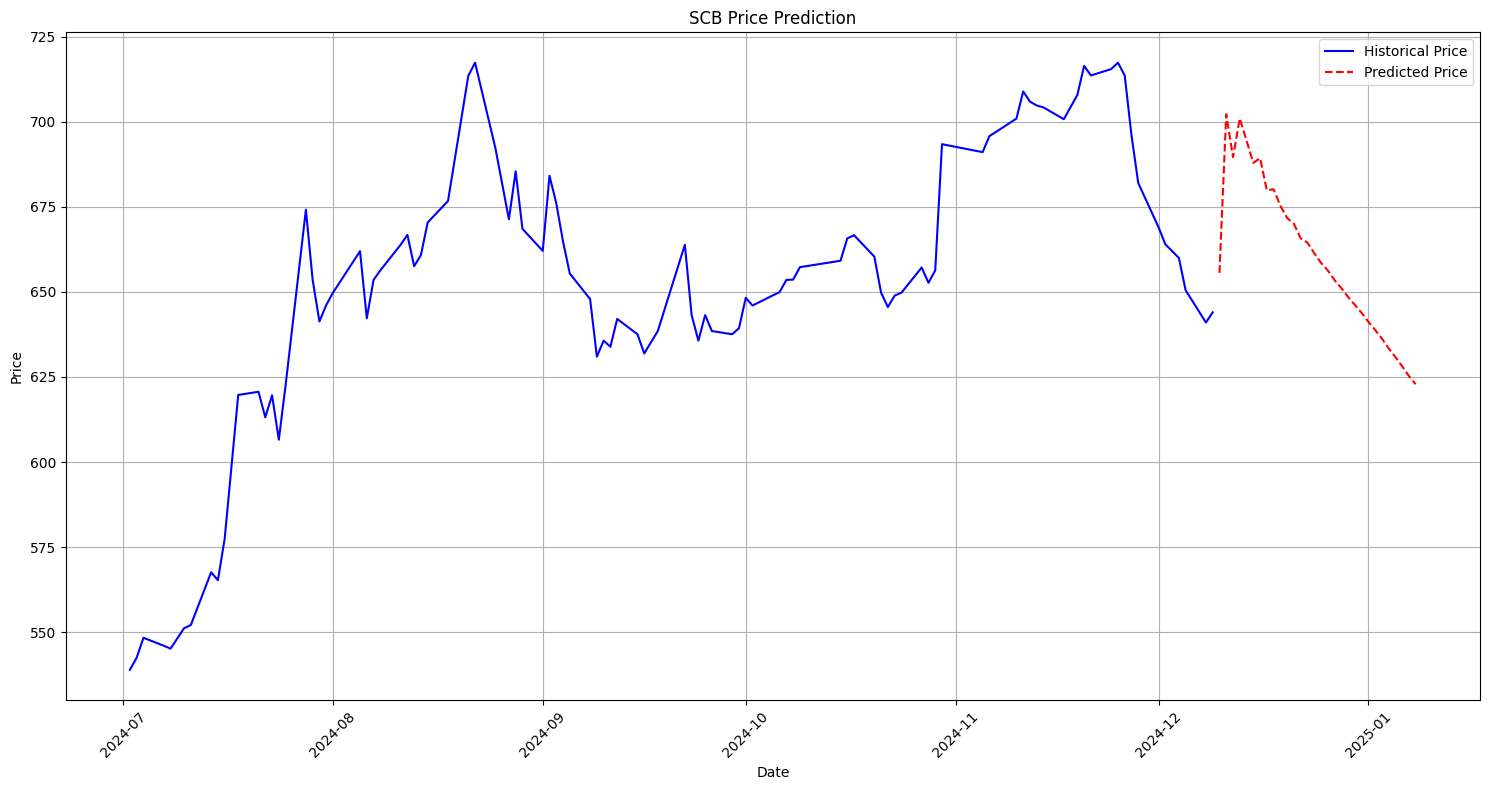

Predictions: [655.61304 702.22064 689.6102  700.97235 694.46967 687.923   689.326
 679.8954  680.1684  675.31256 671.745   670.01416 665.75977 664.4938
 661.4152  658.56586 656.33563 653.4865  651.14667 648.53436 646.1917
 643.862   641.25305 638.82983 636.3005  633.42456 630.85455 628.148
 625.26965 622.8623 ]


In [41]:
if __name__ == "__main__":
    csv_path = 'C:/Users/DELL/Desktop/For Students IOE/Merolagani Nepse Data/ALL STOCK CHARTS/Commercial Banks/SCB.csv'
    predictions, model, scaler = main(csv_path, 'SCB')
    print("Predictions:", predictions)